# Exploratory Analysis

Goal: answer my business questions with numbers and write down what I find.

How each section consists:
1. Question
2. Table or chart
3. What I found 


##  Load the cleaned data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(
    "../data/processed/superstore_clean.csv",
    parse_dates=["Order Date", "Ship Date"],
    keep_default_na=False,
)

In [4]:
df.shape

(9994, 27)

In [5]:
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [6]:
# show 4 bands and no missing values
df["Discount Band"].value_counts()

Discount Band
None      4798
Low       3803
High       933
Medium     460
Name: count, dtype: int64

## Put the discount bands in their natural order.

In [7]:
df["Discount Band"] = pd.Categorical(
    df["Discount Band"],
    categories=["None", "Low", "Medium", "High"],
    ordered=True,
)

##  Overall KPIs

Question: what are the headline numbers?


- Margin = total profit divided by total sales.
- Orders and customers are counted by unique ID, because a row is one order line.

In [8]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
margin = total_profit / total_sales

print("Total sales:", round(total_sales, 2))
print("Total profit:", round(total_profit, 2))
print("Profit margin:", round(margin * 100, 2), "%")
print("Unique orders:", df["Order ID"].nunique())
print("Unique customers:", df["Customer ID"].nunique())

Total sales: 2297200.86
Total profit: 286397.02
Profit margin: 12.47 %
Unique orders: 5009
Unique customers: 793


Average order value: add up sales per order first, then take the average.

In [9]:
order_sales = df.groupby("Order ID")["Sales"].sum()
order_sales.head


<bound method NDFrame.head of Order ID
CA-2011-100006     377.970
CA-2011-100090     699.192
CA-2011-100293      91.056
CA-2011-100328       3.928
CA-2011-100363      21.376
                    ...   
US-2014-168802      18.368
US-2014-169320     171.430
US-2014-169488      56.860
US-2014-169502     113.410
US-2014-169551    1344.838
Name: Sales, Length: 5009, dtype: float64>

In [10]:
order_sales.median()

np.float64(151.96)

Sales are right-skewed,  compare the mean and median of a single order line.

In [11]:
df["Sales"].mean()

np.float64(229.85800083049827)

In [12]:
df["Sales"].median()

np.float64(54.489999999999995)

**What I found:**

-The store made just over 12% profit from all sales 

##  Trends over time

Question: is the business growing, and is there a seasonal pattern?

In [13]:
yearly = df.groupby("Order Year")[["Sales", "Profit"]].sum()
yearly

,Sales,Profit
Order Year,,
2011,484247.4981,49543.9741
2012,470532.5090,61618.6037
2013,608473.8300,81726.9308
2014,733947.0232,93507.5131


<Axes: xlabel='Order Year'>

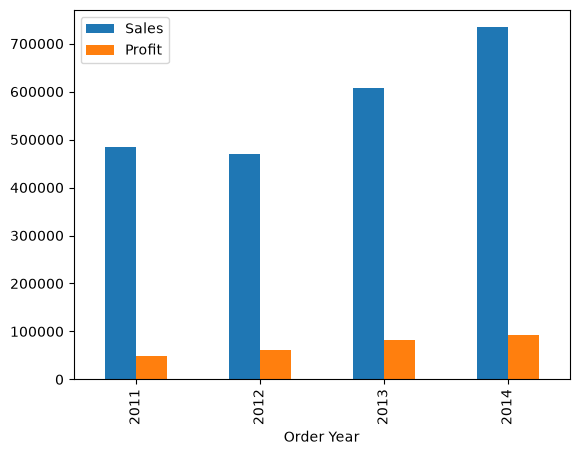

In [14]:
yearly.plot(kind="bar")

<Axes: xlabel='Order Date'>

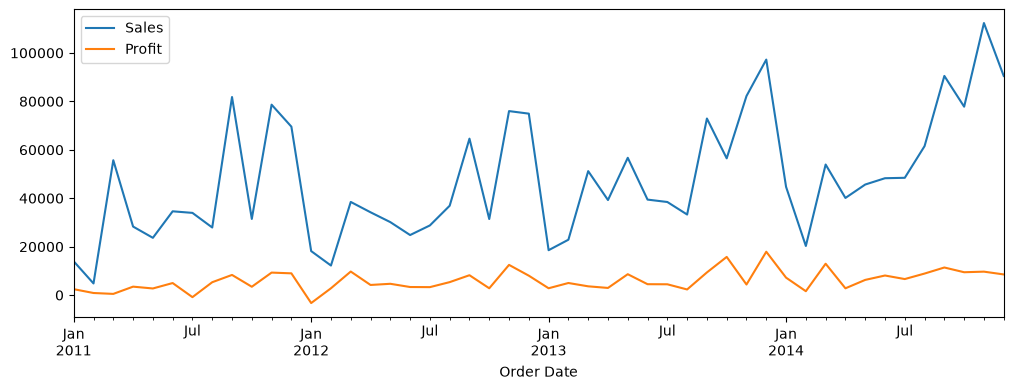

In [15]:
monthly_timeline = df.groupby(df["Order Date"].dt.to_period("M"))[["Sales", "Profit"]].sum()
monthly_timeline.plot(figsize=(12, 4))

Which months are strongest across all years?

<Axes: xlabel='Order Month'>

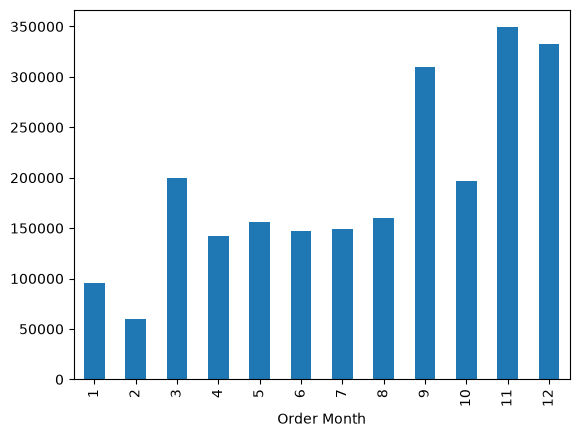

In [16]:
df.groupby("Order Month")["Sales"].sum().plot(kind="bar")

**What I found:**

- November and December where the months with the highest sales where as February was the lowest .

##  Categories and sub-categories

Question: which categories and sub-categories cause the most losses?

Margin here is total profit divided by total sales for each group.

In [17]:
category = df.groupby("Category")[["Sales", "Profit"]].sum()
category["Margin"] = category["Profit"] / category["Sales"]
category

,Sales,Profit,Margin
Category,,,
Furniture,741999.7953,18451.2728,0.024867
Office Supplies,719047.0320,122490.8008,0.170352
Technology,836154.0330,145454.9481,0.173957


In [18]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
sub["Margin"] = sub["Profit"] / sub["Sales"]
sub.sort_values("Profit")

,Sales,Profit,Margin
Sub-Category,,,
Tables,206965.5320,-17725.4811,-0.085645
Bookcases,114879.9963,-3472.5560,-0.030228
Supplies,46673.5380,-1189.0995,-0.025477
Fasteners,3024.2800,949.5182,0.313965
Machines,189238.6310,3384.7569,0.017886
Labels,12486.3120,5546.2540,0.444187
Art,27118.7920,6527.7870,0.240711
Envelopes,16476.4020,6964.1767,0.422676
Furnishings,91705.1640,13059.1436,0.142404


<Axes: ylabel='Sub-Category'>

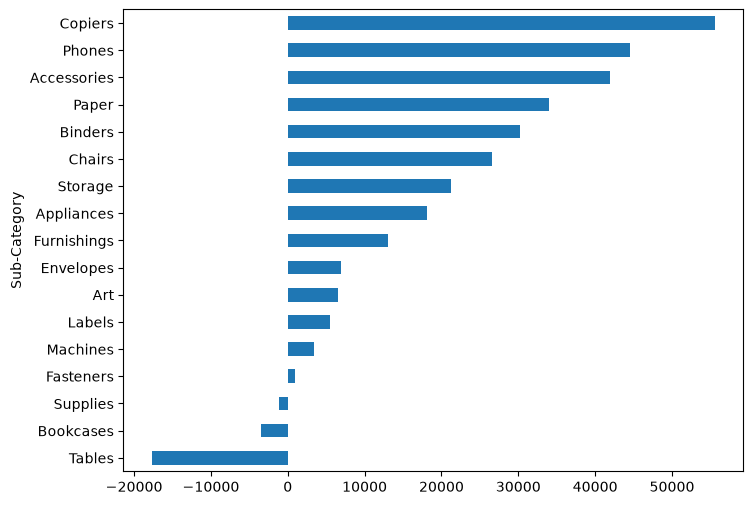

In [19]:
sub["Profit"].sort_values().plot(kind="barh", figsize=(8, 6))

Share of rows that lost money

In [20]:
df.groupby("Sub-Category")["Is Loss"].mean().sort_values(ascending=False)

Sub-Category
Tables         0.636364
Bookcases      0.478070
Binders        0.402495
Machines       0.382609
Chairs         0.380875
Storage        0.190307
Furnishings    0.174504
Supplies       0.173684
Phones         0.152981
Appliances     0.143777
Accessories    0.117419
Fasteners      0.055300
Art            0.000000
Envelopes      0.000000
Copiers        0.000000
Paper          0.000000
Labels         0.000000
Name: Is Loss, dtype: float64

## Total amount lost, counting only loss-making rows.

In [21]:
df[df["Is Loss"]].groupby("Sub-Category")["Profit"].sum().sort_values()

Sub-Category
Binders       -38510.4964
Tables        -32412.1483
Machines      -30118.6682
Bookcases     -12152.2060
Chairs         -9880.8413
Appliances     -8629.6412
Phones         -7530.6235
Furnishings    -6490.9134
Storage        -6426.3038
Supplies       -3015.6219
Accessories     -930.6265
Fasteners        -33.1952
Name: Profit, dtype: float64

**What I found:**

- Most loses came from furniture catergory 

## Regions and states

Question: which region is most profitable?

In [22]:
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin"] = region["Profit"] / region["Sales"]
region

,Sales,Profit,Margin
Region,,,
Central,501239.8908,39706.3625,0.079216
East,678781.2400,91522.7800,0.134834
South,391721.9050,46749.4303,0.119343
West,725457.8245,108418.4489,0.149448


<Axes: xlabel='Region'>

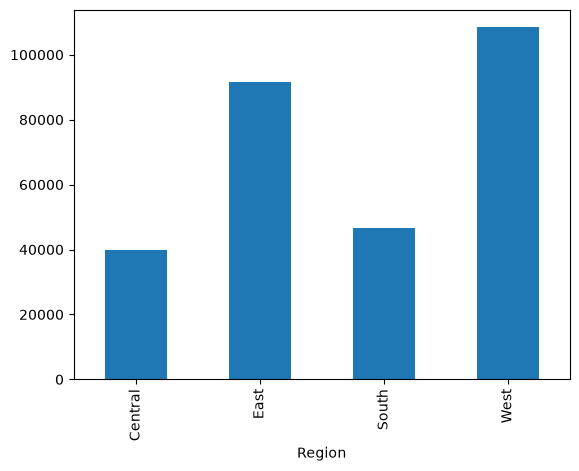

In [23]:
region["Profit"].plot(kind="bar")

In [24]:
state = df.groupby("State")[["Sales", "Profit"]].sum()
state.sort_values("Profit").head(10)

,Sales,Profit
State,,
Texas,170188.0458,-25729.3563
Ohio,78258.1360,-16971.3766
Pennsylvania,116511.9140,-15559.9603
Illinois,80166.1010,-12607.8870
North Carolina,55603.1640,-7490.9122
Colorado,32108.1180,-6527.8579
Tennessee,30661.8730,-5341.6936
Arizona,35282.0010,-3427.9246
Florida,89473.7080,-3399.3017


In [25]:
state.sort_values("Profit").tail(10)

,Sales,Profit
State,,
Delaware,27451.0690,9977.3748
Minnesota,29863.1500,10823.1874
Kentucky,36591.7500,11199.6966
Georgia,49095.8400,16250.0433
Indiana,53555.3600,18382.9363
Virginia,70636.7200,18597.9504
Michigan,76269.6140,24463.1876
Washington,138641.2700,33402.6517
New York,310876.2710,74038.5486


**What I found:**

-By grouping total Sales and Profit by State, we identified the bottom 10 states dragging down overall profitability. Notably, states like Texas and Ohio generate high sales volume but result in significant financial losses 

##  Segments and customers

Question: which segment matters most, and do a few customers make most of the sales?

In [26]:
segment = df.groupby("Segment")[["Sales", "Profit"]].sum()
segment["Margin"] = segment["Profit"] / segment["Sales"]
segment

,Sales,Profit,Margin
Segment,,,
Consumer,1.161401e+06,134119.2092,0.115481
Corporate,7.061464e+05,91979.1340,0.130255
Home Office,4.296531e+05,60298.6785,0.140343


In [27]:
customer_sales = df.groupby("Customer ID")["Sales"].sum().sort_values(ascending=False)
top_20_percent = int(len(customer_sales) * 0.2)
customer_sales.head(top_20_percent).sum() / customer_sales.sum()

np.float64(0.4796190899720081)

The number above is the share of total sales made by the top 20% of customers.

**What I found:**

-By analyzing customer purchasing behavior, we found that the top 20% of customers account for 48% of total sales revenue. Unlike a classic Pareto distribution (80/20), our revenue is relatively evenly distributed across a broader customer base

##  Products

Question: which products sell a lot but lose money?

In [28]:
product = df.groupby("Product Name")[["Sales", "Profit"]].sum()
product.nlargest(10, "Sales")

,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7.753039e+03
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1.811078e+03
HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14
GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03
GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02
Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4.094977e+03
GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03


In [29]:
product.nlargest(10, "Profit")

,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.824,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384,7753.0390
Hewlett Packard LaserJet 3310 Copier,18839.686,6983.8836
Canon PC1060 Personal Laser Copier,11619.834,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895,4094.9766
Ativa V4110MDD Micro-Cut Shredder,7699.890,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.890,3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.290,3696.2820
Ibico EPK-21 Electric Binding System,15875.916,3345.2823


In [30]:
product.nsmallest(10, "Profit")

,Sales,Profit
Product Name,,
Cubify CubeX 3D Printer Double Head Print,11099.963,-8879.9704
Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4589.9730
Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.640,-2876.1156
Bush Advantage Collection Racetrack Conference Table,9544.725,-1934.3976
GBC DocuBind P400 Electric Binding System,17965.068,-1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480,-1811.0784
Martin Yale Chadless Opener Electric Letter Opener,16656.200,-1299.1836
Balt Solid Wood Round Tables,6518.754,-1201.0581


Loss-making products, biggest sellers first.

In [31]:
product[product["Profit"] < 0].nlargest(10, "Sales")

,Sales,Profit
Product Name,,
Cisco TelePresence System EX90 Videoconferencing Unit,22638.4800,-1811.0784
GBC DocuBind P400 Electric Binding System,17965.0680,-1878.1662
High Speed Automatic Electric Letter Opener,17030.3120,-262.0048
Lexmark MX611dhe Monochrome Laser Printer,16829.9010,-4589.9730
Martin Yale Chadless Opener Electric Letter Opener,16656.2000,-1299.1836
"Riverside Palais Royal Lawyers Bookcase, Royale Cherry Finish",15610.9656,-669.5448
Bretford Rectangular Conference Table Tops,12995.2915,-327.2331
Cubify CubeX 3D Printer Double Head Print,11099.9630,-8879.9704
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9917.6400,-2876.1156


**What I found:**

-Some big selling products like printers make accumulate more financial loses than gain for the store 


##  Discount vs profit (the main finding)

Question: Are our discounts actually making us money, or are they just buying us sales volume at the expense of profit?"



In [32]:
discount = df.groupby("Discount Band", observed=True).agg(
    rows=("Sales", "count"),
    total_profit=("Profit", "sum"),
    avg_profit=("Profit", "mean"),
    loss_share=("Is Loss", "mean"),
)
discount

,rows,total_profit,avg_profit,loss_share
Discount Band,,,,
None,4798,320987.6032,66.900292,0.000000
Low,3803,100785.4745,26.501571,0.137523
Medium,460,-35817.4655,-77.864055,0.902174
High,933,-99558.5905,-106.708028,1.000000


<Axes: xlabel='Discount Band'>

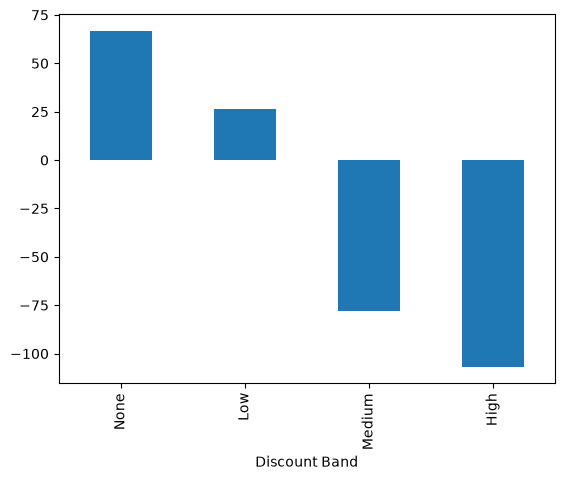

In [33]:
discount["avg_profit"].plot(kind="bar")

<Axes: xlabel='Discount Band'>

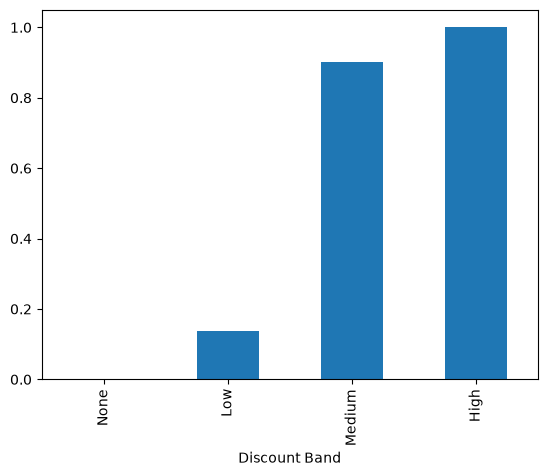

In [34]:
discount["loss_share"].plot(kind="bar")

In [35]:
df[["Discount", "Profit"]].corr()

,Discount,Profit
Discount,1.000000,-0.219487
Profit,-0.219487,1.000000


Which categories get the heaviest discounts? Share of loss-making rows by category and discount band:

In [36]:
df.pivot_table(
    index="Category",
    columns="Discount Band",
    values="Is Loss",
    aggfunc="mean",
    observed=True,
)

Discount Band,None,Low,Medium,High
Category,,,,
Furniture,0.0,0.251682,0.953704,1.0
Office Supplies,0.0,0.092918,NaN,1.0
Technology,0.0,0.154211,0.779412,1.0


**What I found:**

-Discount Risk is Highly Concentrated in the Furniture Category

## Shipping 

Question: how long does each ship mode take?

In [37]:
df.groupby("Ship Mode")["Ship Days"].mean()

Ship Mode
First Class       2.182055
Same Day          0.044199
Second Class      3.240103
Standard Class    5.007205
Name: Ship Days, dtype: float64

##  Key findings



**1**.Aggressive Discounting is the Root Cause of Massive Losses

**2**."Furniture" is the Most Fragile Category (Category-Specific Discount Risk)

**3**.High Sales Volume Does Not Equal High Profit 

**4**.Severe Seasonality Causes a dip in Profitability in Q1

**5**. Revenue is Driven by a Broad Base, Not Just a Few "Whales"

**Recommendations :**

-implement a Hard Cap on Discounts

-Adopt a Category-Specific Discount Strategy

- **Investigate the loss-making states before changing prices.**
   Six states (Texas, Ohio, Pennsylvania, Illinois, North Carolina and Colorado) generated about $533K in sales but lost about $85K, a combined margin of -15.9%. Texas alone lost about $25.7K on $170K in sales. Check whether heavy discounting or a weak product mix explains the losses, then adjust accordingly.